# Fase 1 — Preparación y análisis exploratorio

Material de apoyo elaborado con asistencia de IA. El grupo debe revisar y asumir las decisiones metodológicas e interpretar los resultados antes de entregar. No se fabrican observaciones individuales.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = next(p for p in [Path.cwd(), Path.cwd().parent] if (p / 'protocolo.json').exists())
sys.path.insert(0, str(ROOT / 'src'))
from common import OUT, PROTOCOL
from data_prep import main as preparar
if not (ROOT / 'data/processed/serie_mensual.csv').exists():
    _ = preparar()
pd.set_option('display.max_columns', 15)
pd.set_option('display.max_colwidth', 100)
display(Markdown('**Protocolo temporal:** desarrollo 2016–2022; calibración 2023; prueba 2024.'))


**Protocolo temporal:** desarrollo 2016–2022; calibración 2023; prueba 2024.

## Pregunta y unidad

¿Con qué precisión podemos pronosticar doce cantidades mensuales de siniestros registrados por la Caminera en Central e Interior, frente a referencias sencillas? Una fila es un mes, no una víctima. La fecha representa el primer día del período mensual.

## Reconstrucción desde originales

La función siguiente lee los siete XLSX, verifica sus hashes, controla componentes y totales, conserva versiones y produce el CSV. La implementación auditable está en `src/data_prep.py`; no utiliza tablas modificadas a mano.

In [2]:
_ = preparar()
auditoria = json.loads((OUT / 'auditoria_datos.json').read_text(encoding='utf-8'))
display(pd.DataFrame([auditoria]).T.rename(columns={0:'Resultado'}))

Fase 1 - preparacion: {'archivos': 7, 'filas_extraidas': 168, 'filas_finales': 108, 'duplicados_coincidentes': 60, 'guiones_convertidos': 100, 'meses_faltantes': 0, 'objetivos_imputados': 0, 'sumas_inconsistentes': 0, 'totales_anuales_validados': 14, 'distribucion_particiones': {'Desarrollo': 84, 'Calibracion': 12, 'Prueba': 12}, 'fuente': 'INE; Patrulla Caminera, zona Central e Interior', 'limite': 'Coherencia verificada; estabilidad institucional de cobertura no demostrada'}


,Resultado
archivos,7
filas_extraidas,168
filas_finales,108
duplicados_coincidentes,60
guiones_convertidos,100
meses_faltantes,0
objetivos_imputados,0
sumas_inconsistentes,0
totales_anuales_validados,14
distribucion_particiones,"{'Desarrollo': 84, 'Calibracion': 12, 'Prueba': 12}"


In [3]:
serie = pd.read_csv(ROOT / 'data/processed/serie_mensual.csv', parse_dates=['fecha'])
assert serie['fecha'].is_unique and len(serie) == 108
display(serie.head())
display(pd.read_csv(OUT / 'tables/bitacora_limpieza.csv'))

,fecha,accidentes,choque,roce,vuelco,arrollamiento,incendio,...,edicion,ano,mes,semestre,dias_mes,tasa_diaria_mes,particion
0,2016-01-01,127,79,28,12,0,0,...,2017,2016,1,Primero,31,4.096774,Desarrollo
1,2016-02-01,141,107,21,8,0,0,...,2017,2016,2,Primero,29,4.862069,Desarrollo
2,2016-03-01,154,111,29,7,0,0,...,2017,2016,3,Primero,31,4.967742,Desarrollo
3,2016-04-01,149,98,37,8,1,0,...,2017,2016,4,Primero,30,4.966667,Desarrollo
4,2016-05-01,146,104,30,5,0,1,...,2017,2016,5,Primero,31,4.709677,Desarrollo


,operacion,cantidad_afectada,fundamento
0,Seleccion,7,Siete cuadros de tipologia con mismo alcance publicado; resto no se suma.
1,Extraccion,168,"Filas mensuales; se excluyen titulos, fuentes y totales anuales."
2,Guiones a cero,100,Solo en componentes categoricos; las sumas por fila y ano se conservan. No se imputan meses.
3,Versiones repetidas,60,Coinciden todos los conteos; se conserva la edicion mas reciente y se guardan todas las versiones.
4,Normalizar fecha,108,"Primer dia representa el mes, no una fecha de accidente individual."
5,Atipicos,0,No se eliminan ni winsorizan meses validos; los cambios pueden ser reales.
6,Imputar objetivo,0,No hay faltantes ni meses inventados.
7,Separar tiempo,108,84 desarrollo; 12 calibracion; 12 prueba.


## Diccionarios y calidad

Los guiones solo se convierten en ceros en los componentes validados. No hay objetivos imputados. Se conserva la procedencia por celda y no se eliminan extremos legítimos.

In [4]:
display(pd.read_csv(OUT / 'tables/diccionario_original.csv'))
display(pd.read_csv(OUT / 'tables/diccionario_final.csv'))

,columna_original,significado,tipo_original,unidad,rango,faltantes_pct,guiones,observacion
0,B,Ano o nombre del mes,texto,ano / mes calendario,Enero a diciembre en cada bloque anual,0,0,Solo filas mensuales; no es identificador de accidente
1,C,Total de siniestros,entero,siniestros/mes,31 a 231,0,0,Encabezados anuales separados como controles
2,D,choque,entero o guion,siniestros/mes,23 a 190; guion si corresponde,0,0,Guion interpretado como cero solo tras validar sumas
3,E,roce,entero o guion,siniestros/mes,0 a 37; guion si corresponde,0,0,Guion interpretado como cero solo tras validar sumas
4,F,vuelco,entero o guion,siniestros/mes,3 a 23; guion si corresponde,0,0,Guion interpretado como cero solo tras validar sumas
5,G,arrollamiento,entero o guion,siniestros/mes,0 a 6; guion si corresponde,0,44,Guion interpretado como cero solo tras validar sumas
6,H,incendio,entero o guion,siniestros/mes,0 a 3; guion si corresponde,0,54,Guion interpretado como cero solo tras validar sumas
7,I,casual,entero o guion,siniestros/mes,0 a 19; guion si corresponde,0,2,Guion interpretado como cero solo tras validar sumas
8,J,atropellamiento,entero o guion,siniestros/mes,0 a 18; guion si corresponde,0,0,Guion interpretado como cero solo tras validar sumas


,campo,descripcion,tipo,unidad,faltantes_pct,cardinalidad,minimo_o_ejemplo,maximo_o_ejemplo
0,fecha,Clave temporal mensual unica; primer dia del mes,str,mes calendario,0.0,108,2016-01-01,2024-12-01
1,accidentes,Variable objetivo: total registrado,int64,siniestros/mes,0.0,72,31,231
2,choque,"Componente del total; descriptivo, excluido como predictor contemporaneo",int64,siniestros/mes,0.0,62,23,190
3,roce,"Componente del total; descriptivo, excluido como predictor contemporaneo",int64,siniestros/mes,0.0,28,0,37
4,vuelco,"Componente del total; descriptivo, excluido como predictor contemporaneo",int64,siniestros/mes,0.0,19,3,23
5,arrollamiento,"Componente del total; descriptivo, excluido como predictor contemporaneo",int64,siniestros/mes,0.0,6,0,6
6,incendio,"Componente del total; descriptivo, excluido como predictor contemporaneo",int64,siniestros/mes,0.0,4,0,3
7,casual,"Componente del total; descriptivo, excluido como predictor contemporaneo",int64,siniestros/mes,0.0,14,0,19
8,atropellamiento,"Componente del total; descriptivo, excluido como predictor contemporaneo",int64,siniestros/mes,0.0,18,0,18
9,archivo,Documento original conservado,str,texto,0.0,7,INE_2017_tipologia_2016_2017.xlsx,INE_2024_tipologia_2023_2024.xlsx


## Exploración de desarrollo

Se excluyen 2023 y 2024 de la exploración. Las medias anteriores destinadas a modelado están desplazadas; las medias móviles contemporáneas de un gráfico descriptivo no se convierten en predictores del mismo mes.

In [5]:
from phase1 import main as explorar
resultado = explorar()
display(pd.read_csv(OUT / 'tables/descriptivos_desarrollo.csv'))
display(pd.read_csv(OUT / 'tables/resumen_por_mes_desarrollo.csv'))

Fase 1 - EDA: 84 meses; 10 graficos; prueba y calibracion fuera de la exploracion.


,variable,n,media,mediana,moda,desv_est,cv,...,asimetria,curtosis_exceso,p5,p25,p50,p75,p95
0,accidentes,84,141.928571,140.500000,141,34.130785,0.240479,...,0.053395,1.048331,91.20,123.000000,140.500000,154.250000,201.850000
1,tasa_diaria_mes,84,4.661048,4.636905,3.5; 4.0; 4.290322580645161; 4.354838709677419; 4.548387096774194; 4.67741935483871; 4.709677419...,1.108163,0.237750,...,0.026545,1.089299,3.05,4.080645,4.636905,5.024194,6.610968


,mes,count,mean,median,std,min,max
0,1,7,136.857143,133.0,18.836388,111,173
1,2,7,128.285714,129.0,17.394580,98,152
2,3,7,133.571429,135.0,24.227100,88,163
3,4,7,131.714286,147.0,47.094636,31,174
4,5,7,137.857143,146.0,29.248525,73,158
5,6,7,142.142857,140.0,30.350335,90,187
6,7,7,156.571429,149.0,37.362446,119,231
7,8,7,155.142857,152.0,34.236572,114,195
8,9,7,146.571429,131.0,46.889434,100,222
9,10,7,143.000000,129.0,43.393548,106,205


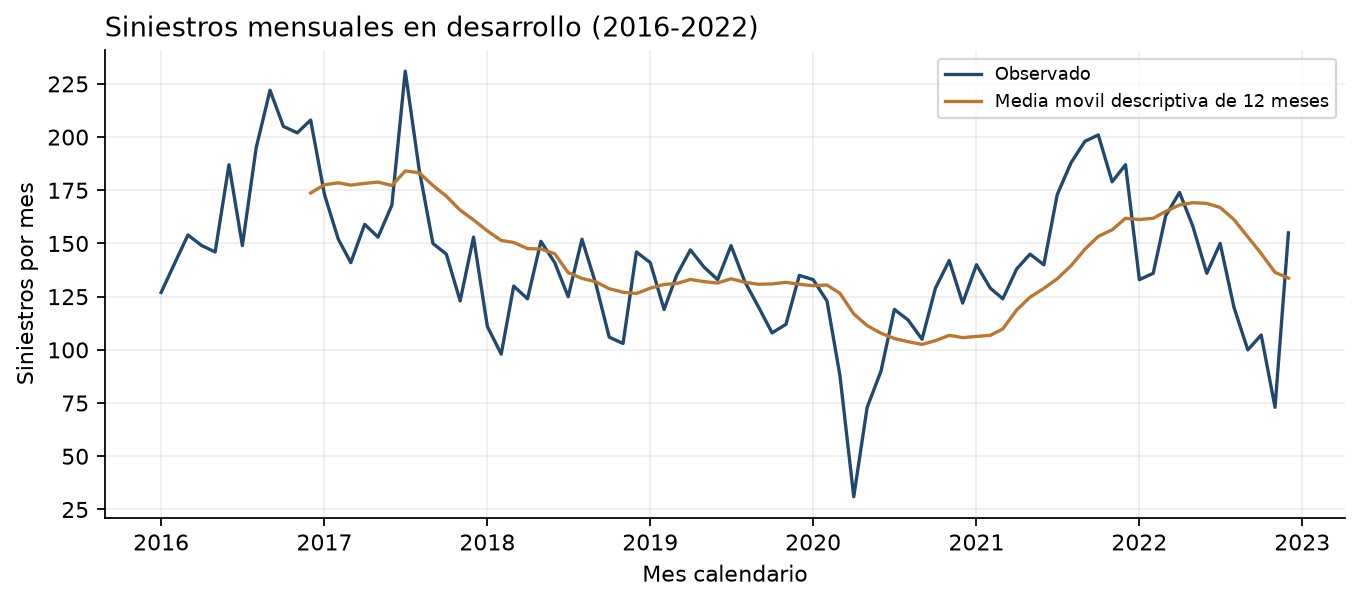

In [6]:
display(Image(filename=str(OUT / 'figures/f1_01_serie.png')))

Los conteos van de 31 a 231 por mes. La media movil describe el historial; no se usa para pronosticar el mismo mes.

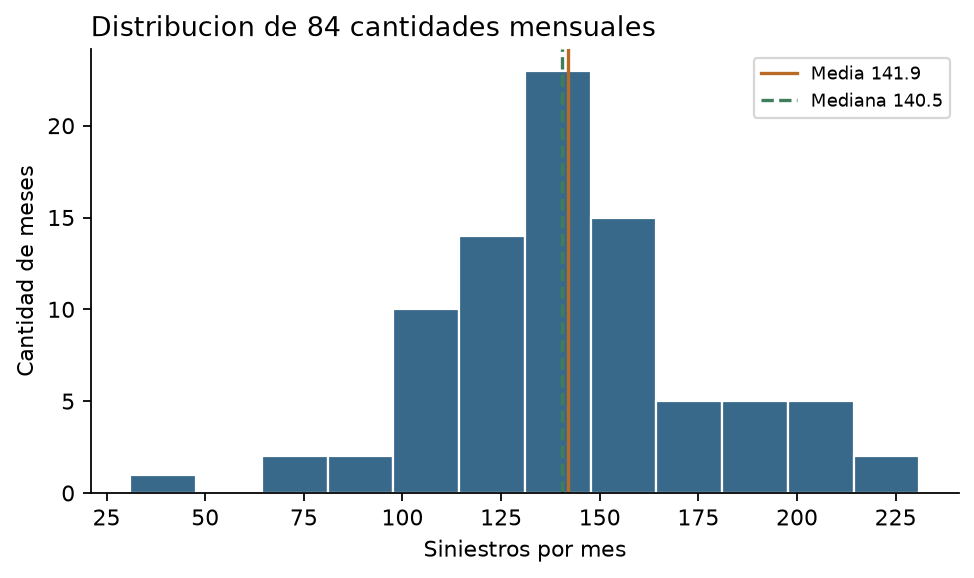

In [7]:
display(Image(filename=str(OUT / 'figures/f1_02_histograma.png')))

La asimetria es 0.05. La media resume el nivel, pero mezcla anos con contextos distintos; tambien se informa la mediana.

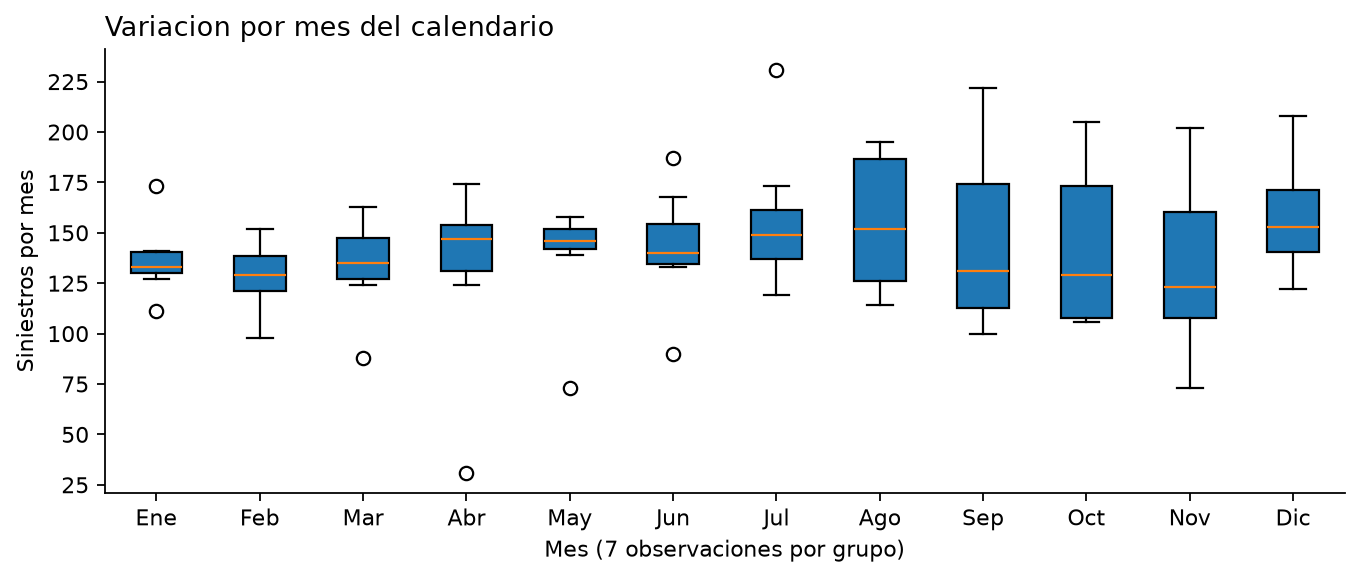

In [8]:
display(Image(filename=str(OUT / 'figures/f1_03_cajas_mes.png')))

Cada caja resume siete anos del mismo mes. La superposicion muestra que el mes del calendario por si solo no determina el conteo.

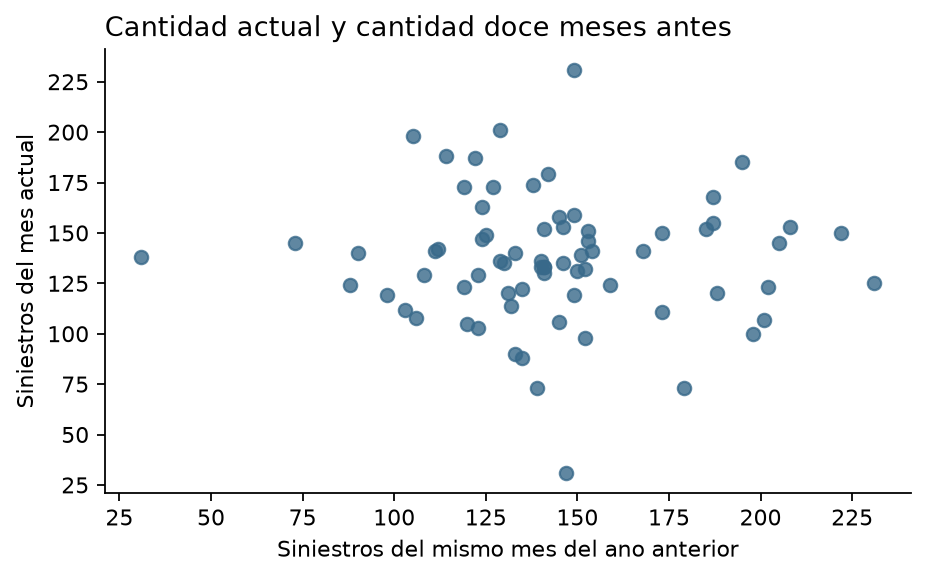

In [9]:
display(Image(filename=str(OUT / 'figures/f1_04_dispersion.png')))

La correlacion de Pearson es -0.04; la de Spearman es -0.00. No demuestran causalidad ni sustituyen la validacion de pronosticos.

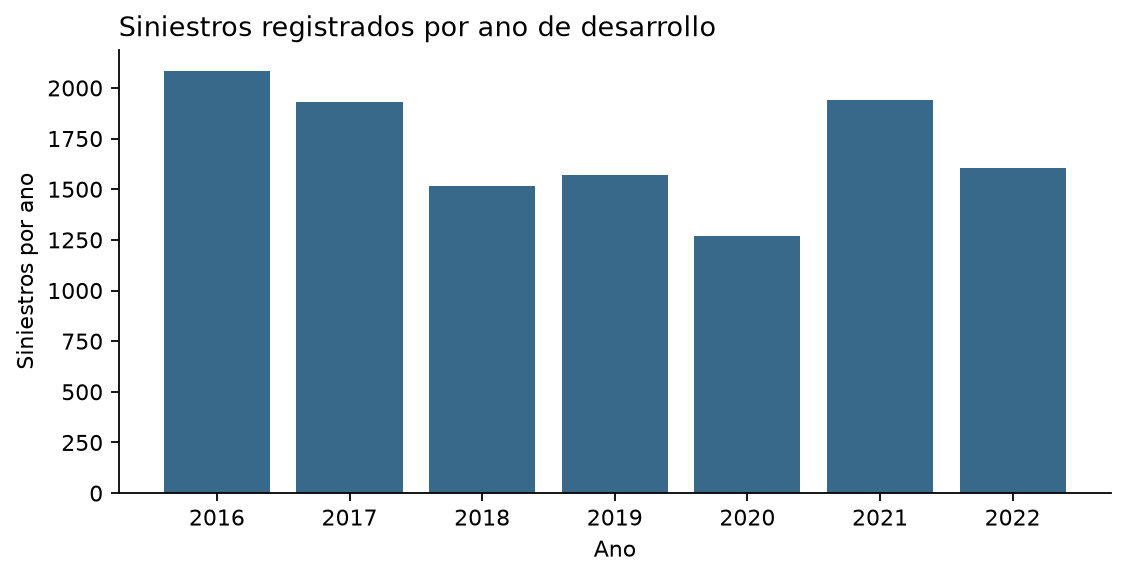

In [10]:
display(Image(filename=str(OUT / 'figures/f1_05_barras_ano.png')))

El total anual minimo es 1269 y el maximo 2085. La variacion requiere considerar cambios reales y posibles cambios en registro o cobertura.

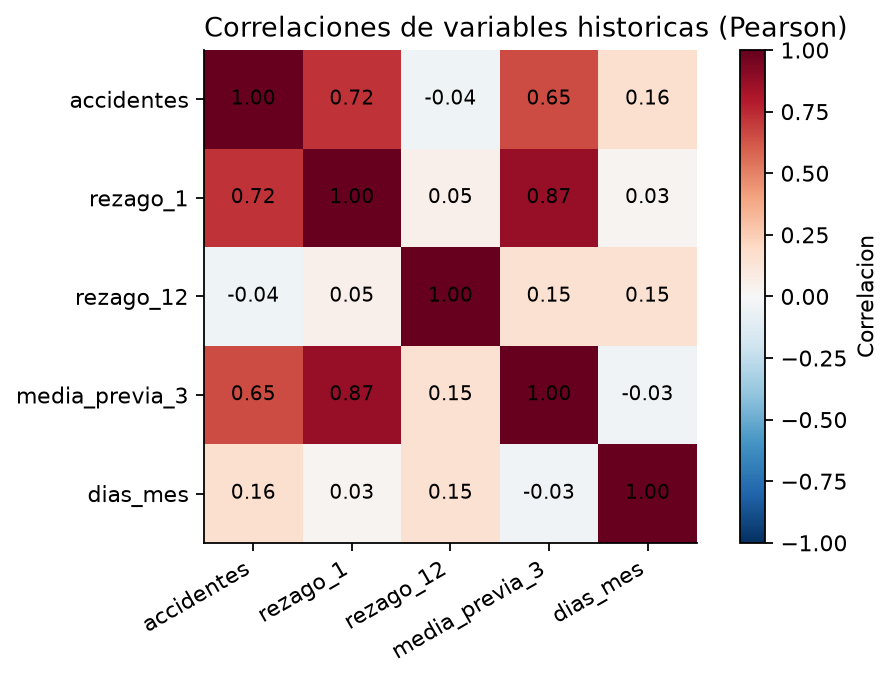

In [11]:
display(Image(filename=str(OUT / 'figures/f1_06_correlaciones.png')))

Los rezagos y medias anteriores pueden estar correlacionados entre si. Se excluyen los componentes del total del mismo mes para no filtrar la respuesta.

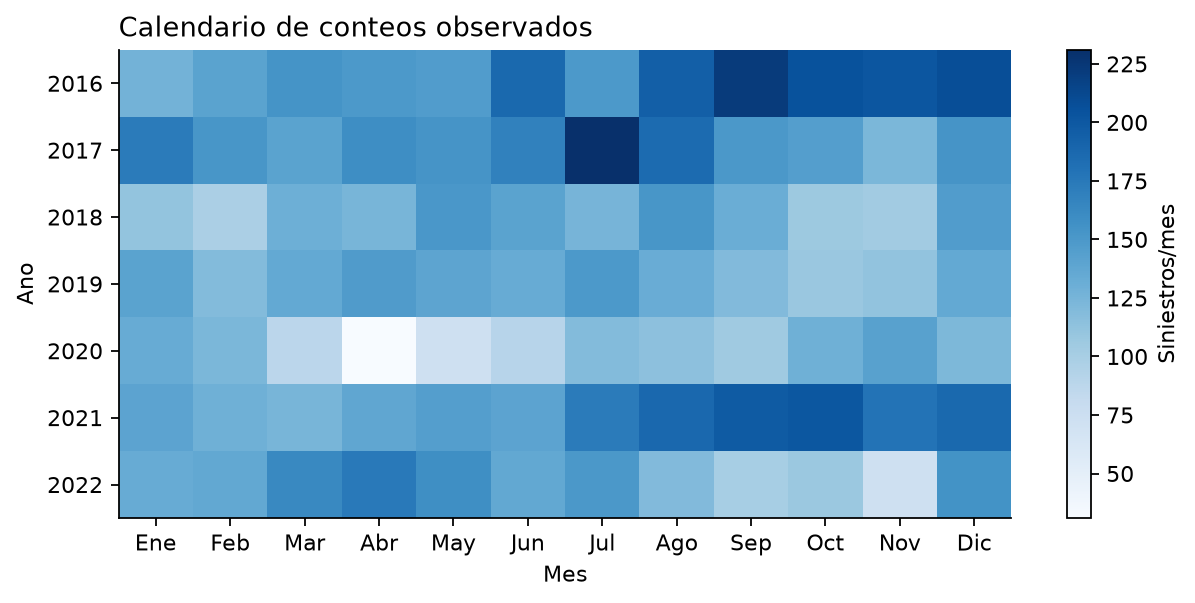

In [12]:
display(Image(filename=str(OUT / 'figures/f1_07_calendario.png')))

El calendario distingue anos y meses con niveles diferentes. No se rellenan con cero periodos ausentes; los 84 periodos de desarrollo estan publicados.

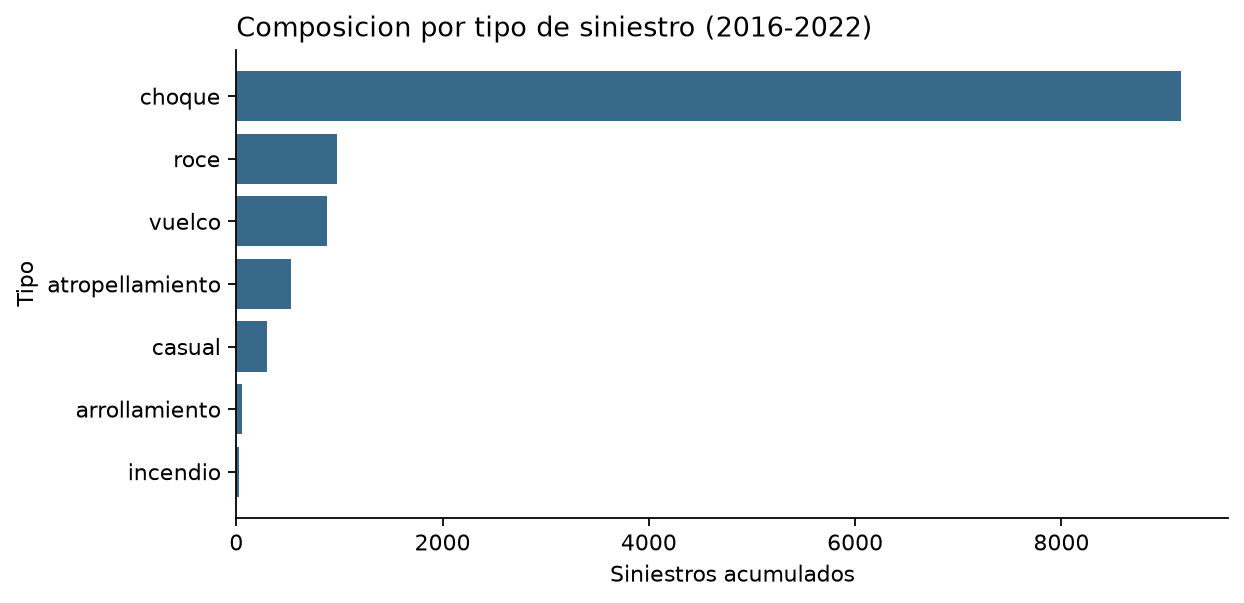

In [13]:
display(Image(filename=str(OUT / 'figures/f1_08_tipos.png')))

Las dos categorias mas frecuentes concentran 85.0% del total. Son 2 de 7 categorias (28,6%), no exactamente el 20%.

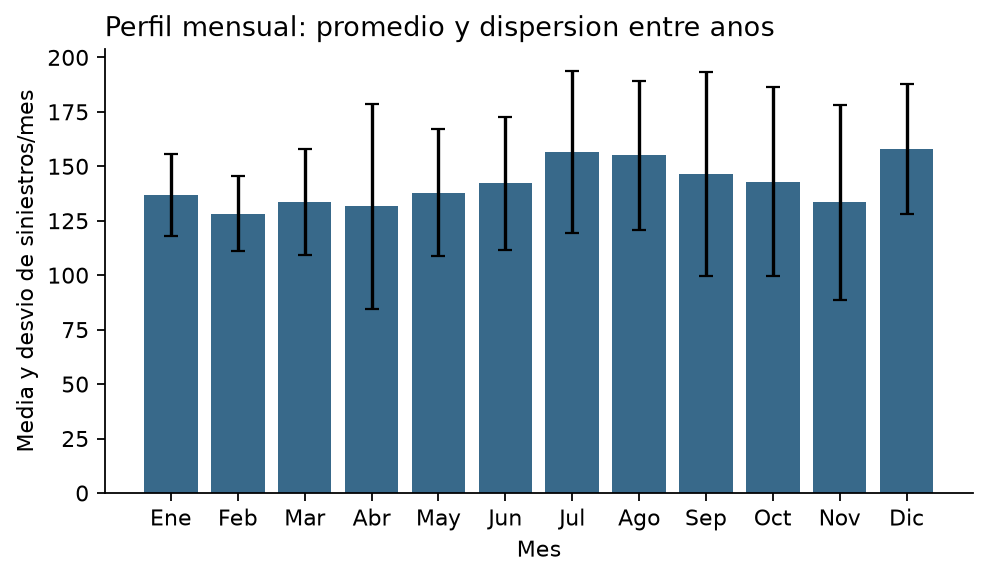

In [14]:
display(Image(filename=str(OUT / 'figures/f1_09_perfil.png')))

Las barras de error representan dispersion entre anos, no intervalos de confianza ni bandas de pronostico. La estacionalidad se contrasta en la Fase 2.

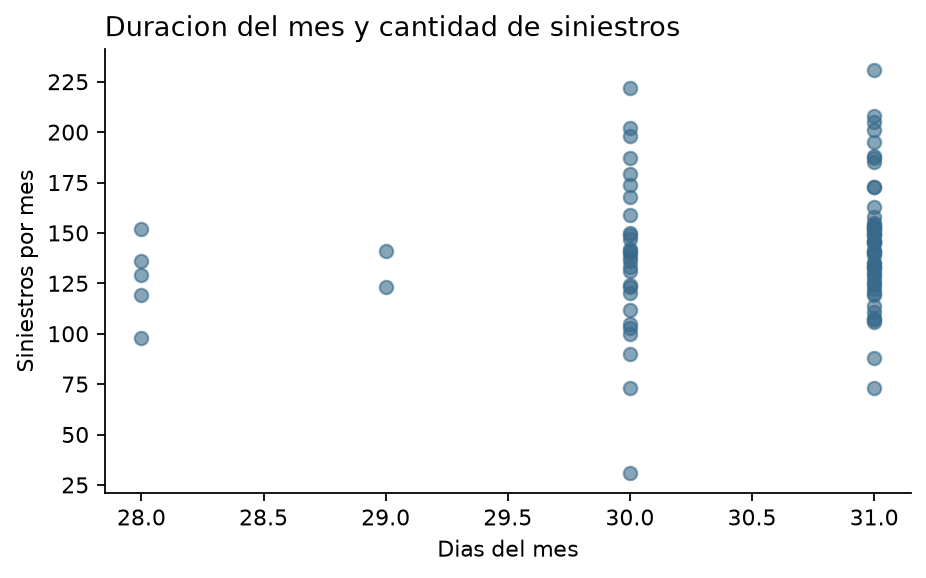

In [15]:
display(Image(filename=str(OUT / 'figures/f1_10_exposicion.png')))

Un mes mas largo ofrece mas dias de observacion, pero dias del mes no equivale a kilometros recorridos o volumen de transito. No se estima riesgo por viaje.

## Tablas bivariadas y concentraciones

Las tablas de contingencia describen conteos de siniestros por semestre y tipo. No se unen artificialmente cuadros para asignar características a personas.

In [16]:
display(pd.read_csv(OUT / 'tables/contingencia_semestre_tipo_absoluta.csv'))
display(pd.read_csv(OUT / 'tables/contingencia_semestre_tipo_por_fila.csv'))
display(pd.read_csv(OUT / 'tables/contingencia_semestre_tipo_por_columna.csv'))
display(pd.read_csv(OUT / 'tables/frecuencias_tipos_desarrollo.csv'))

,semestre,choque,roce,vuelco,arrollamiento,incendio,casual,atropellamiento
0,Primero,4358,459,413,23,13,147,260
1,Segundo,4802,513,462,35,9,154,274


,semestre,choque,roce,vuelco,arrollamiento,incendio,casual,atropellamiento
0,Primero,76.820025,8.090957,7.280099,0.405429,0.229156,2.591222,4.583113
1,Segundo,76.844295,8.209313,7.393183,0.560090,0.144023,2.464394,4.384702


,semestre,choque,roce,vuelco,arrollamiento,incendio,casual,atropellamiento
0,Primero,47.576419,47.222222,47.2,39.655172,59.090909,48.837209,48.689139
1,Segundo,52.423581,52.777778,52.8,60.344828,40.909091,51.162791,51.310861


,tipo,cantidad,porcentaje
0,choque,9160,76.832746
1,roce,972,8.152994
2,vuelco,875,7.339373
3,atropellamiento,534,4.479114
4,casual,301,2.524744
5,arrollamiento,58,0.486496
6,incendio,22,0.184533


## Conclusión y cuatro hipótesis

La serie permite una comparación temporal, pero el número de períodos es pequeño y la cobertura no está validada externamente. Se contrastarán alineación mensual (H1), diferencia entre semestres (H2), tendencia anual (H3) y asociación condicional con el rezago uno (H4). No se exige que todas resulten significativas. Los resultados no describen riesgo por viaje ni causalidad.